# 06 - Important Features Summary

**Project:** German Credit Risk
**Input:** `data/processed/german_credit_engineered.csv` (created by notebook 05)
**Author:** Divya Akbari

**Goal of this notebook**
1. Complete the WoE / IV analysis by checking **how much each feature really adds** to prediction.
2. Rank the features and group them into **importance tiers**.
3. Summarise each important feature: its riskiest and safest bands and what they mean.

Three measures of importance are used:

| Measure | What it shows |
|---|---|
| **Information Value (IV)** | How well the feature separates good and bad customers **on its own** |
| **Drop-one AUC loss** | How much cross-validated ROC-AUC falls when the feature is **removed** from the model (its *unique* contribution) |
| **Contribution share** | Each feature's share of the model's total effect (coefficient x spread of its WoE values) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', None)

fe = pd.read_csv('data/processed/german_credit_engineered.csv')
fe['housing'] = fe['Housing']
fe['sex'] = fe['Sex']
print(fe.shape)

(1000, 28)


In [2]:
names = {
    'checking_status': 'Checking account status', 'duration_bin': 'Duration', 'saving_status': 'Saving account status',
    'credit_bin': 'Credit amount', 'age_bin': 'Age', 'housing': 'Housing', 'payment_bin': 'Monthly payment',
    'purpose_group': 'Purpose group', 'low_balance_profile': 'Low balance profile', 'sex': 'Sex', 'job_group': 'Job group',
}
# The 8 features selected in notebook 05, in order of IV
selected = ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'age_bin', 'housing', 'payment_bin', 'purpose_group']
excluded = {'low_balance_profile': 'Overlaps with checking account status (r = 0.64)',
            'sex': 'Protected characteristic', 'job_group': 'No useful signal (IV below 0.02)'}

def woe_table(data, feature):
    table = pd.crosstab(data[feature], data['bad'])
    good, bad = table[0], table[1]
    good_share = (good + 0.5) / good.sum()
    bad_share = (bad + 0.5) / bad.sum()
    woe = np.log(good_share / bad_share)
    return pd.DataFrame({'Customers': good + bad, 'Bad rate (%)': (bad / (good + bad) * 100).round(1),
                         'WoE': woe.round(3), 'IV part': (good_share - bad_share) * woe})

## 1. Information Value of every feature

In [3]:
iv = pd.DataFrame({'Feature': list(names), 'Name': list(names.values())})
iv['IV'] = [round(woe_table(fe, f)['IV part'].sum(), 3) for f in iv['Feature']]
iv['Status'] = ['Selected' if f in selected else 'Excluded' for f in iv['Feature']]
iv = iv.sort_values('IV', ascending=False).reset_index(drop=True)
iv

,Feature,Name,IV,Status
0,checking_status,Checking account status,0.662,Selected
1,low_balance_profile,Low balance profile,0.327,Excluded
2,duration_bin,Duration,0.230,Selected
3,saving_status,Saving account status,0.189,Selected
4,credit_bin,Credit amount,0.142,Selected
5,age_bin,Age,0.093,Selected
6,housing,Housing,0.084,Selected
7,payment_bin,Monthly payment,0.077,Selected
8,purpose_group,Purpose group,0.066,Selected
9,sex,Sex,0.027,Excluded


## 2. How much does each feature add? (drop-one test)

The model is trained on all 8 selected features, then again with **one feature removed**.
The fall in cross-validated ROC-AUC shows what that feature adds that the others do not already cover.
WoE values are learned on the training part of each fold only, and the 5-fold split is repeated 5 times with different
random seeds so that the result does not depend on one lucky split.

In [4]:
SEEDS = [42, 7, 123, 2024, 99]

def cross_validated_auc(features):
    scores = []
    for seed in SEEDS:
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        for train_idx, test_idx in folds.split(fe, fe['bad']):
            train, test = fe.iloc[train_idx], fe.iloc[test_idx]
            X_train, X_test = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)
            for f in features:
                mapping = woe_table(train, f)['WoE']
                X_train[f] = train[f].map(mapping)
                X_test[f] = test[f].map(mapping).fillna(0)
            model = LogisticRegression(max_iter=1000).fit(X_train, train['bad'])
            scores.append(roc_auc_score(test['bad'], model.predict_proba(X_test)[:, 1]))
    return np.mean(scores)

full_auc = cross_validated_auc(selected)
print('ROC-AUC with all 8 features (5 x 5-fold):', round(full_auc, 3))

ROC-AUC with all 8 features (5 x 5-fold): 0.774


In [5]:
rows = []
for f in selected:
    auc_without = cross_validated_auc([x for x in selected if x != f])
    rows.append([names[f], round(auc_without, 4), round(full_auc - auc_without, 4)])
drop_one = pd.DataFrame(rows, columns=['Feature', 'AUC without it', 'AUC loss']).sort_values('AUC loss', ascending=False).reset_index(drop=True)
drop_one

,Feature,AUC without it,AUC loss
0,Checking account status,0.7135,0.0603
1,Monthly payment,0.7643,0.0095
2,Credit amount,0.7645,0.0093
3,Saving account status,0.7684,0.0054
4,Duration,0.7697,0.0041
5,Age,0.7699,0.0039
6,Housing,0.7716,0.0022
7,Purpose group,0.7723,0.0015


## 3. Contribution share in the final model
Each feature's contribution is its coefficient multiplied by the spread (standard deviation) of its WoE values,
shown as a share of the total.

In [6]:
X = pd.DataFrame({f: fe[f].map(woe_table(fe, f)['WoE']) for f in selected})
model = LogisticRegression(max_iter=1000).fit(X, fe['bad'])
contribution = np.abs(model.coef_[0]) * X.std().values
share = pd.DataFrame({'Feature': [names[f] for f in selected], 'Coefficient': model.coef_[0].round(3),
                      'Contribution (%)': (contribution / contribution.sum() * 100).round(1)})
share = share.sort_values('Contribution (%)', ascending=False).reset_index(drop=True)
share

,Feature,Coefficient,Contribution (%)
0,Checking account status,-0.847,28.5
1,Credit amount,-0.918,13.0
2,Saving account status,-0.710,12.7
3,Monthly payment,-1.171,12.3
4,Duration,-0.625,11.9
5,Age,-0.736,8.6
6,Purpose group,-0.657,6.7
7,Housing,-0.571,6.3


## 4. How quickly does performance build up?
Features are added one at a time in order of IV, and the cross-validated ROC-AUC is measured at each step.

In [7]:
steps = []
for k in range(1, len(selected) + 1):
    steps.append([k, '+ ' + names[selected[k - 1]], round(cross_validated_auc(selected[:k]), 4)])
build_up = pd.DataFrame(steps, columns=['Features used', 'Feature added', 'ROC-AUC'])
build_up['Gain'] = build_up['ROC-AUC'].diff().fillna(build_up['ROC-AUC'] - 0.5).round(4)
build_up

,Features used,Feature added,ROC-AUC,Gain
0,1,+ Checking account status,0.7080,0.2080
1,2,+ Duration,0.7449,0.0369
2,3,+ Saving account status,0.7504,0.0055
3,4,+ Credit amount,0.7576,0.0072
4,5,+ Age,0.7605,0.0029
5,6,+ Housing,0.7633,0.0028
6,7,+ Monthly payment,0.7723,0.0090
7,8,+ Purpose group,0.7738,0.0015


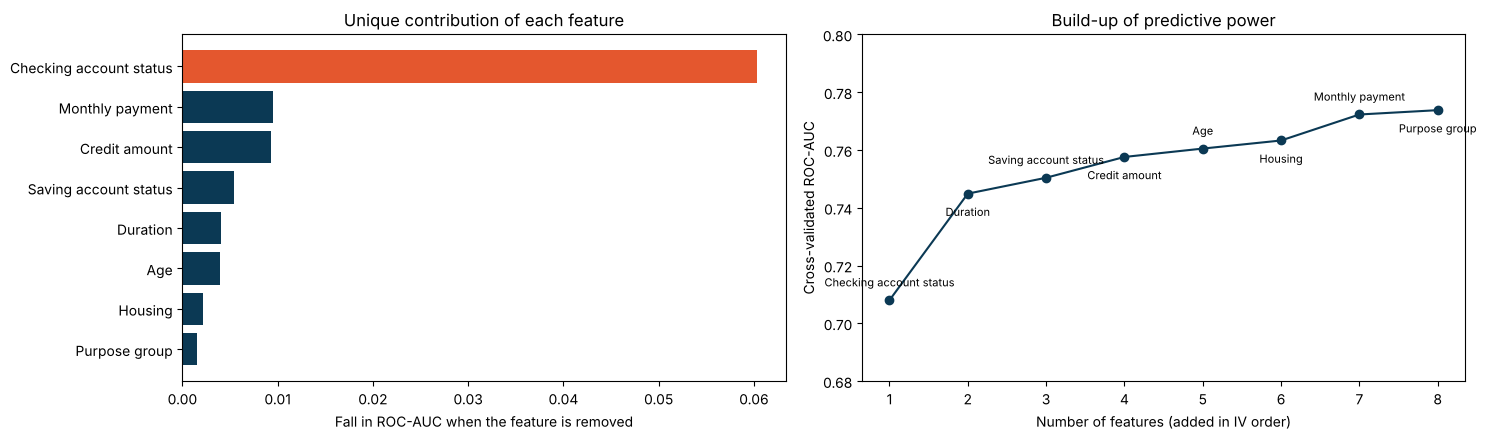

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

d = drop_one.iloc[::-1]
axes[0].barh(d['Feature'], d['AUC loss'], color=['#E4572E' if v > 0.02 else '#0B3954' for v in d['AUC loss']])
axes[0].set_xlabel('Fall in ROC-AUC when the feature is removed')
axes[0].set_title('Unique contribution of each feature')

axes[1].plot(build_up['Features used'], build_up['ROC-AUC'], marker='o', color='#0B3954')
for i, r in build_up.iterrows():
    above = i % 2 == 0                      # alternate labels above and below the line
    axes[1].annotate(r['Feature added'].replace('+ ', ''), (r['Features used'], r['ROC-AUC']),
                     textcoords='offset points', xytext=(0, 10 if above else -16), ha='center', fontsize=8)
axes[1].set_xlabel('Number of features (added in IV order)')
axes[1].set_ylabel('Cross-validated ROC-AUC')
axes[1].set_title('Build-up of predictive power')
axes[1].set_ylim(0.68, 0.80)
plt.tight_layout()
plt.show()

## 5. Importance tiers

The three measures are combined into tiers:
- **Tier 1 - Critical:** very strong IV **and** the largest unique contribution.
- **Tier 2 - Important:** medium IV (0.1 to 0.3) or a clear unique contribution (AUC loss of at least 0.005).
- **Tier 3 - Supporting:** weak IV and a small unique contribution; useful but not essential.
- **Excluded:** not used in the model (see notebook 05 for the reasons).

In [9]:
loss = drop_one.set_index('Feature')['AUC loss']
contrib = share.set_index('Feature')['Contribution (%)']
ivs = iv.set_index('Feature')['IV']

def tier(f):
    if f not in selected:
        return 'Excluded'
    if ivs[f] >= 0.5 and loss[names[f]] == loss.max():
        return 'Tier 1 - Critical'
    if ivs[f] >= 0.1 or loss[names[f]] >= 0.005:
        return 'Tier 2 - Important'
    return 'Tier 3 - Supporting'

summary = pd.DataFrame({'Feature': [names[f] for f in iv['Feature']], 'IV': iv['IV'].values})
summary['AUC loss'] = [loss.get(names[f], np.nan) for f in iv['Feature']]
summary['Contribution (%)'] = [contrib.get(names[f], np.nan) for f in iv['Feature']]
summary['Tier'] = [tier(f) for f in iv['Feature']]
summary['Note'] = [excluded.get(f, '') for f in iv['Feature']]
tier_order = {'Tier 1 - Critical': 0, 'Tier 2 - Important': 1, 'Tier 3 - Supporting': 2, 'Excluded': 3}
summary = summary.sort_values(['Tier', 'IV'], key=lambda s: s.map(tier_order) if s.name == 'Tier' else -s).reset_index(drop=True)
summary

,Feature,IV,AUC loss,Contribution (%),Tier,Note
0,Checking account status,0.662,0.0603,28.5,Tier 1 - Critical,
1,Duration,0.230,0.0041,11.9,Tier 2 - Important,
2,Saving account status,0.189,0.0054,12.7,Tier 2 - Important,
3,Credit amount,0.142,0.0093,13.0,Tier 2 - Important,
4,Monthly payment,0.077,0.0095,12.3,Tier 2 - Important,
5,Age,0.093,0.0039,8.6,Tier 3 - Supporting,
6,Housing,0.084,0.0022,6.3,Tier 3 - Supporting,
7,Purpose group,0.066,0.0015,6.7,Tier 3 - Supporting,
8,Low balance profile,0.327,NaN,NaN,Excluded,Overlaps with checking account status (r = 0.64)
9,Sex,0.027,NaN,NaN,Excluded,Protected characteristic


## 6. Profile of each important feature
For every selected feature: the safest and riskiest band, the gap in bad rate between them, and the WoE of each band.

In [10]:
rows = []
for f in selected:
    t = woe_table(fe, f)
    safe, risky = t['WoE'].idxmax(), t['WoE'].idxmin()
    rows.append([names[f], tier(f), safe, t.loc[safe, 'Bad rate (%)'], risky, t.loc[risky, 'Bad rate (%)'],
                 round(t.loc[risky, 'Bad rate (%)'] - t.loc[safe, 'Bad rate (%)'], 1)])
profiles = pd.DataFrame(rows, columns=['Feature', 'Tier', 'Safest band', 'Bad rate safest (%)', 'Riskiest band',
                                       'Bad rate riskiest (%)', 'Gap (points)'])
profiles

,Feature,Tier,Safest band,Bad rate safest (%),Riskiest band,Bad rate riskiest (%),Gap (points)
0,Checking account status,Tier 1 - Critical,no account,11.7,little,49.3,37.6
1,Duration,Tier 2 - Important,up to 11,15.0,36+,48.2,33.2
2,Saving account status,Tier 2 - Important,quite rich/rich,15.3,little,36.0,20.7
3,Credit amount,Tier 2 - Important,"1,501-4,000",23.9,"over 7,500",51.2,27.3
4,Age,Tier 3 - Supporting,34+,24.6,25 or under,42.1,17.5
5,Housing,Tier 3 - Supporting,own,26.1,free,40.7,14.6
6,Monthly payment,Tier 2 - Important,over 150,25.5,up to 80,41.6,16.1
7,Purpose group,Tier 3 - Supporting,radio/TV,22.1,education/other,38.1,16.0


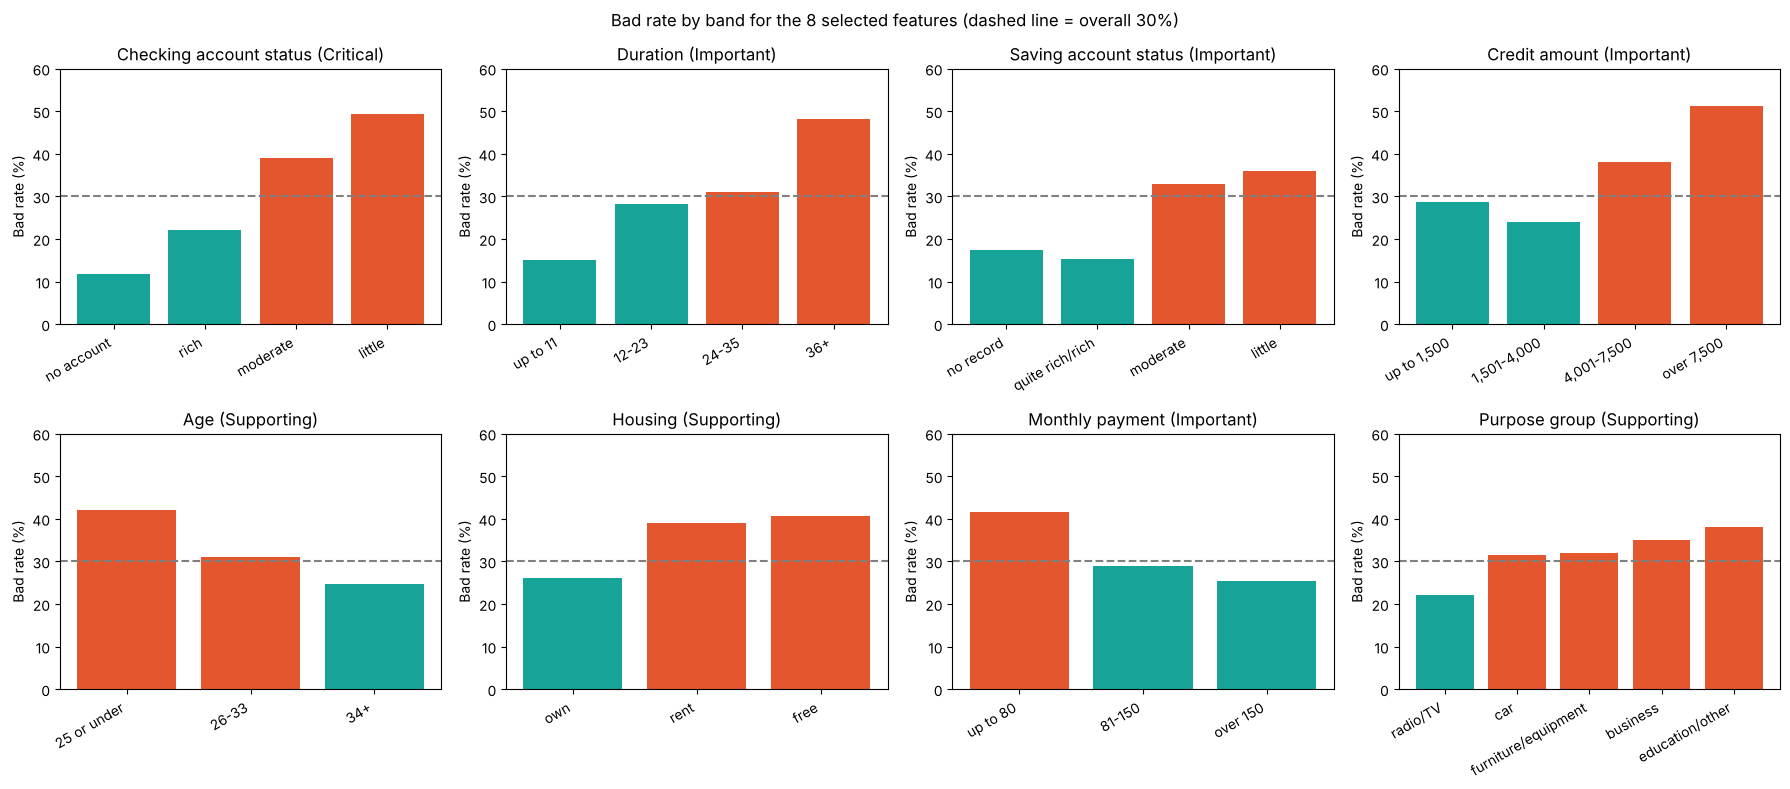

In [11]:
order = {
    'checking_status': ['no account', 'rich', 'moderate', 'little'], 'duration_bin': ['up to 11', '12-23', '24-35', '36+'],
    'saving_status': ['no record', 'quite rich/rich', 'moderate', 'little'],
    'credit_bin': ['up to 1,500', '1,501-4,000', '4,001-7,500', 'over 7,500'], 'age_bin': ['25 or under', '26-33', '34+'],
    'housing': ['own', 'rent', 'free'], 'payment_bin': ['up to 80', '81-150', 'over 150'],
    'purpose_group': ['radio/TV', 'car', 'furniture/equipment', 'business', 'education/other'],
}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.flatten(), selected):
    t = woe_table(fe, f).loc[order[f]]
    ax.bar(t.index, t['Bad rate (%)'], color=['#E4572E' if v > 30 else '#17A398' for v in t['Bad rate (%)']])
    ax.axhline(30, color='grey', linestyle='--')
    ax.set_title(f'{names[f]} ({tier(f).split(" - ")[1]})')
    ax.set_ylabel('Bad rate (%)')
    ax.set_ylim(0, 60)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.suptitle('Bad rate by band for the 8 selected features (dashed line = overall 30%)')
plt.tight_layout()
plt.show()

## 7. Quick checks

In [12]:
checks = {
    'Dataset has 1,000 customers': len(fe) == 1000,
    'All 8 selected features have an IV of at least 0.02': (iv.set_index('Feature').loc[selected, 'IV'] >= 0.02).all(),
    'Checking account status has the highest IV': iv.loc[0, 'Feature'] == 'checking_status',
    'Removing any feature lowers the ROC-AUC': (drop_one['AUC loss'] > 0).all(),
    'Contribution shares add up to 100%': abs(share['Contribution (%)'].sum() - 100) < 0.5,
    'All model coefficients are negative (expected sign)': (model.coef_[0] < 0).all(),
    'ROC-AUC rises from the first to the last step of the build-up': build_up['ROC-AUC'].iloc[-1] > build_up['ROC-AUC'].iloc[0],
    'Exactly one Tier 1 feature': (summary['Tier'] == 'Tier 1 - Critical').sum() == 1,
    'Protected characteristic (Sex) is excluded': summary.set_index('Feature').loc['Sex', 'Tier'] == 'Excluded',
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Dataset has 1,000 customers
PASS - All 8 selected features have an IV of at least 0.02
PASS - Checking account status has the highest IV
PASS - Removing any feature lowers the ROC-AUC
PASS - Contribution shares add up to 100%
PASS - All model coefficients are negative (expected sign)
PASS - ROC-AUC rises from the first to the last step of the build-up
PASS - Exactly one Tier 1 feature
PASS - Protected characteristic (Sex) is excluded

All 9 checks passed


## 8. Summary of important features

**Tier 1 - Critical**
- **Checking account status** is by far the most important feature. It has a very strong IV and removing it costs more ROC-AUC than any other feature.
  Applicants with no recorded checking account are the safest group; those with a "little" balance are the riskiest.

**Tier 2 - Important**
- **Duration, Saving account status, Credit amount and Monthly payment** each add clear predictive power.
  Duration has a medium IV but a smaller unique contribution, because Credit amount and Monthly payment (credit / duration) already carry much of its information.

**Tier 3 - Supporting**
- **Age, Housing and Purpose group** have weak IVs and add a little extra accuracy.

**Excluded**
- **Low balance profile** (overlaps with checking account), **Sex** (protected characteristic) and **Job group** (no useful signal).

With all 8 selected features the model reaches a cross-validated ROC-AUC of about **0.77** (Gini about 0.55).
Checking account alone gives about 0.71, and the first three features together give 0.75.